In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
print("Kich Thuoc Tep train:", X_train.shape, y_train.shape)
print("Kich thuoc tep test:", X_test.shape, y_test.shape)

Kich Thuoc Tep train: (60000, 28, 28) (60000,)
Kich thuoc tep test: (10000, 28, 28) (10000,)


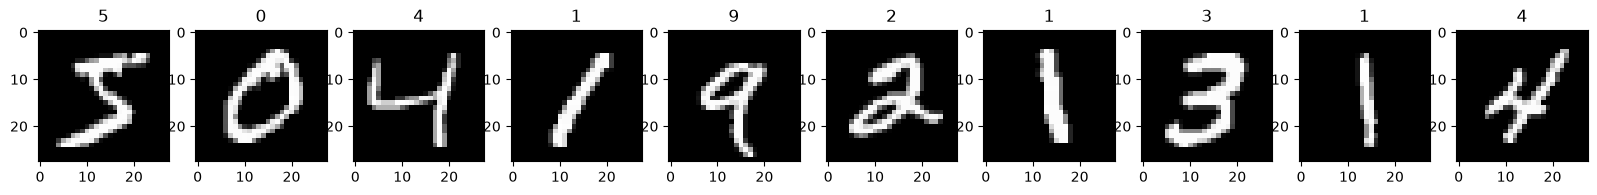

In [10]:
fig, axes = plt.subplots(nrows=1, ncols=10, figsize=(20, 3))
for i in range(10):
    axes[i].imshow(X_train[i], cmap='gray')
    axes[i].set_title(y_train[i])
plt.show()

In [11]:
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255

#Bo sung chieu kenh mau o cuoi : (28, 28) -> (28, 28, 1)
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print("Kich thuoc X_train sau khi them chieu:", X_train.shape)
print("Kich thuoc X_test sau khi them chieu:", X_test.shape)

Kich thuoc X_train sau khi them chieu: (60000, 28, 28, 1)
Kich thuoc X_test sau khi them chieu: (10000, 28, 28, 1)


In [13]:
n_classes = 10
y_train_en = keras.utils.to_categorical(y_train, n_classes)
y_test_en = keras.utils.to_categorical(y_test, n_classes)

print("Kich thuoc nhan sau ma hoa:", y_train_en.shape, y_test_en.shape)
print("Nhan goc:", y_train[0], "-> Sau ma hoa:", y_train_en[0])

Kich thuoc nhan sau ma hoa: (60000, 10) (10000, 10)
Nhan goc: 5 -> Sau ma hoa: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [15]:
model = Sequential([
    Conv2D(filters=32, kernel_size=(3, 3), activation = 'relu', input_shape=(28, 28, 1), padding='same'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(filters=64, kernel_size=(3, 3), activation ='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(n_classes, activation='softmax')
])

model.summary()

/opt/homebrew/Caskroom/miniconda/base/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
log = model.fit(X_train, y_train_en, batch_size=128, epochs=10, validation_split=0.1)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9056 - loss: 0.3088 - val_accuracy: 0.9845 - val_loss: 0.0580
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9696 - loss: 0.1031 - val_accuracy: 0.9890 - val_loss: 0.0423
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9783 - loss: 0.0759 - val_accuracy: 0.9895 - val_loss: 0.0367
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9817 - loss: 0.0620 - val_accuracy: 0.9898 - val_loss: 0.0371
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9850 - loss: 0.0496 - val_accuracy: 0.9907 - val_loss: 0.0340
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9869 - loss: 0.0434 - val_accuracy: 0.9908 - val_loss: 0.0376
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9883 - loss: 0.0377 - val_accuracy: 0.9910 - val_loss: 0.0339
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9890 - loss: 0.0349 - val_accu

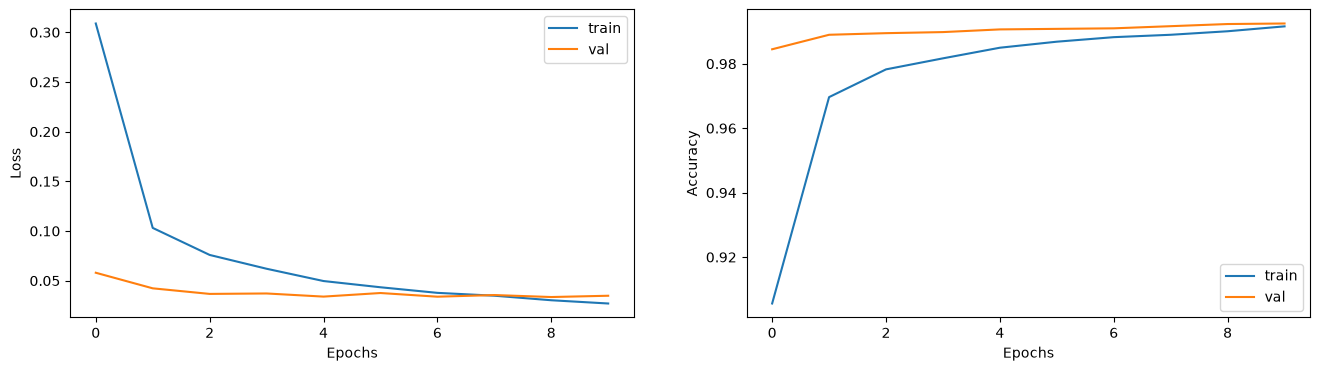

In [22]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 4))

axes[0].plot(log.history['loss'], label='train')
axes[0].plot(log.history['val_loss'], label='val')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(log.history['accuracy'], label='train')
axes[1].plot(log.history['val_accuracy'], label='val')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
10 ket qua du doan dau tien: [7 2 1 0 4 1 4 9 5 9]


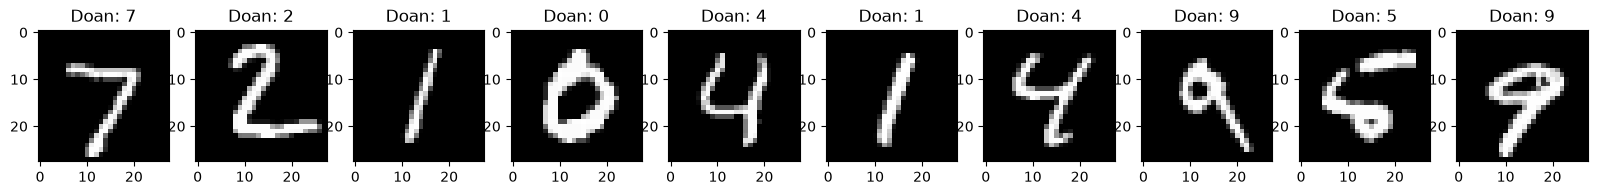

In [23]:
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

print("10 ket qua du doan dau tien:", y_pred[:10])

fig, axes = plt.subplots(nrows=1, ncols=10, figsize=(20, 3))
for i in range(10):
    axes[i].imshow(X_test[i].reshape(28, 28), cmap='gray')
    axes[i].set_title(f"Doan: {y_pred[i]}")

plt.show()

Tong so anh bi doan sai tren 10.000 ah: 81


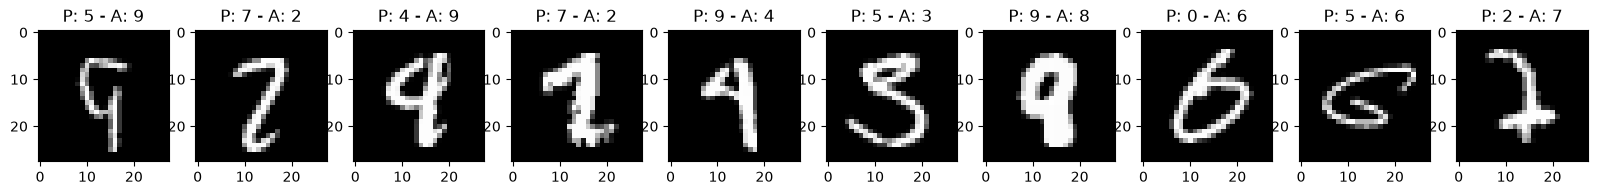

In [25]:
incorrect_indexes = np.where(y_pred != y_test)[0]
print("Tong so anh bi doan sai tren 10.000 ah:", incorrect_indexes.shape[0])

fig, axes = plt.subplots(nrows=1, ncols=10, figsize=(20, 3))
for i in range(10):
    idx = incorrect_indexes[i]
    axes[i].imshow(X_test[idx].reshape(28, 28), cmap='gray')
    axes[i].set_title(f"P: {y_pred[idx]} - A: {y_test[idx]}")
plt.show()

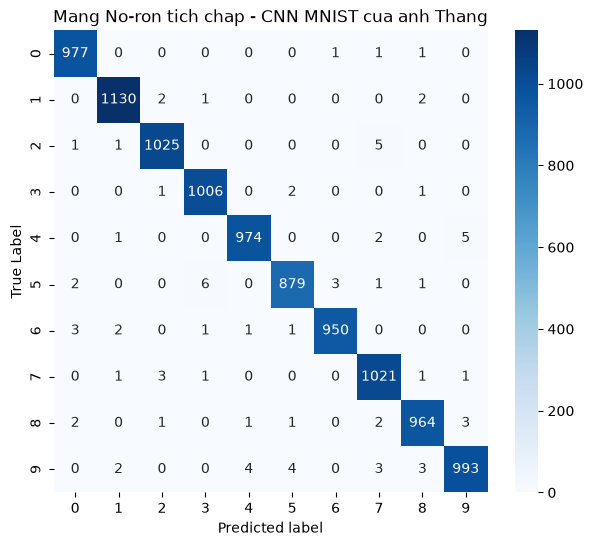

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

So luong chu so 8 bi doan nham: 10


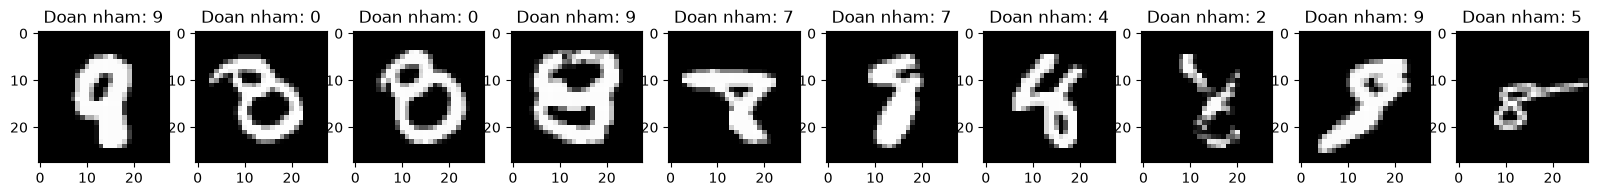

In [33]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Mang No-ron tich chap - CNN MNIST cua anh Thang')
plt.xlabel('Predicted label')
plt.ylabel('True Label')
plt.show()

print(classification_report(y_test, y_pred))

incorrect_eight_indexes = np.where((y_pred !=8) & (y_test == 8))[0]
print("So luong chu so 8 bi doan nham:", len(incorrect_eight_indexes))

fig, axes = plt.subplots(nrows=1, ncols=10, figsize=(20, 3))
for i, idx in enumerate(incorrect_eight_indexes[:10]):
    axes[i].imshow(X_test[idx].reshape(28, 28), cmap='gray')
    axes[i].set_title(f"Doan nham: {y_pred[idx]}")
plt.show()